In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse
from sklearn.cluster import KMeans

from src.adaptive_clustering import adaptive_clustering
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad

DOMAIN = [-2, 3]
N = 10_000
SEED = 0
TOL = 0.1

/home/prajwal/github-repos/knnsur/src/__init__.py:18: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


In [ ]:
import numpy as np


def estimate_hessian_sqrt_single(X, G_X, mu, G_mu, epsilon=1e-10):
    """
    Estimates the symmetric |H|^1/2 for a single cluster.

    Args:
        X: (N, d) Matrix of positions.
        G_X: (N, 1, d) Matrix of gradients.
        mu: (1, d) Centroid.
        G_mu: (1, 1, d) Gradient at the centroid.
    """
    # 1. Standardize shapes to (N, d) and (d,)
    # squeeze() removes all dimensions of size 1
    # ravel() ensures the subtraction targets are flat vectors
    dX = X - np.ravel(mu)  # (N, d) - (d,) -> (N, d)

    # Squeeze G_X from (N, 1, d) to (N, d)
    # Squeeze G_mu from (1, 1, d) to (d,)
    clean_G_X = np.squeeze(G_X)
    clean_G_mu = np.ravel(G_mu)

    dG = clean_G_X - clean_G_mu  # (N, d) - (d,) -> (N, d)

    # 2. Compute second-moment matrices
    # (d, N) @ (N, d) -> (d, d)
    C = dX.T @ dX
    E = dX.T @ dG

    # Symmetrize and prepare S
    C = 0.5 * (C + C.T)
    S = E + E.T

    # 3. Solve HC + CH = S
    dvals, U = np.linalg.eigh(C)
    dvals = np.maximum(dvals, epsilon)

    G_tilde = U.T @ S @ U
    denom = dvals[:, None] + dvals[None, :]
    F = G_tilde / denom

    # 4. Compute |H|^1/2
    h_eigvals, V = np.linalg.eigh(F)
    Z = U @ V
    w_abs_sqrt = np.sqrt(np.abs(h_eigvals))

    M = (Z * w_abs_sqrt) @ Z.T

    return 0.5 * (M + M.T)

Text(0, 0.5, '$x_2$')

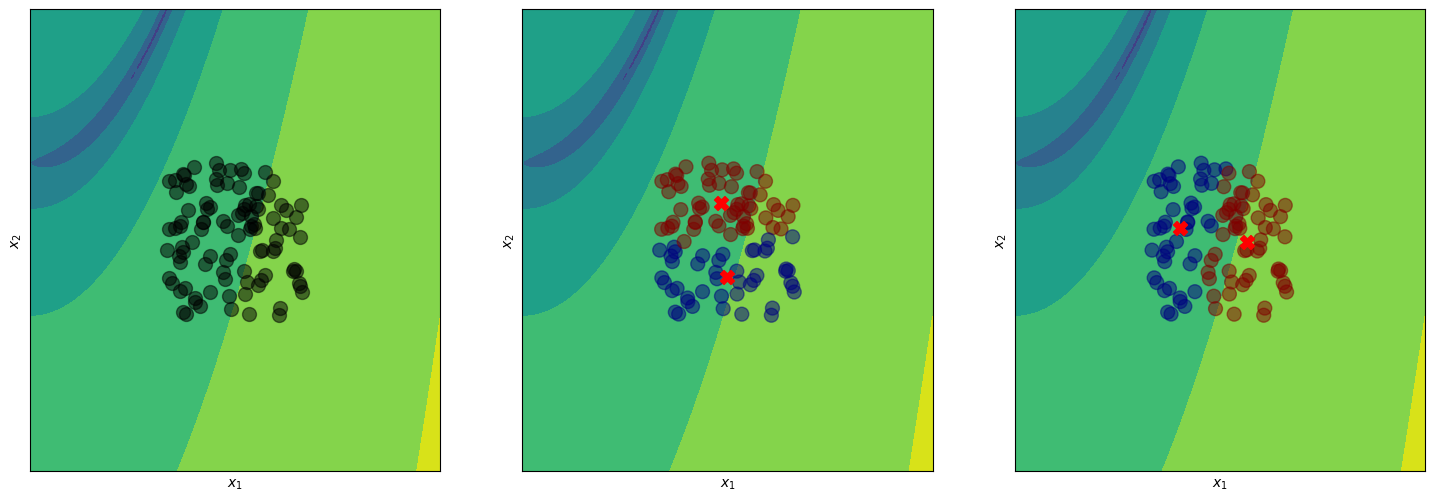

In [ ]:
DOMAIN = [-2, 3]
xlim = [0, 3]
ylim = [-2, 1]

np.random.seed(SEED)
x_domain = [1, 2]
y_domain = [-1, 0]
N = 100
_x = np.random.uniform(x_domain[0], x_domain[1], N)
_y = np.random.uniform(y_domain[0], y_domain[1], N)
points = np.stack([_x, _y], axis=1)

# Plot countrf
x = np.linspace(DOMAIN[0], DOMAIN[1], 200)
y = np.linspace(DOMAIN[0], DOMAIN[1], 200)
X, Y = np.meshgrid(x, y)
Z = rosenbrock(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)

# Plot points on top
points_size = 100
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.contourf(X, Y, Z, levels=50, cmap="viridis", norm=LogNorm())
plt.scatter(points[:, 0], points[:, 1], s=points_size, color="black", alpha=0.5)
plt.xlim(xlim)
plt.ylim(ylim)
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.xticks([])
plt.yticks([])


plt.subplot(1, 3, 2)
# perform k-means clustering for k=2
kmeans = KMeans(n_clusters=2, random_state=SEED).fit(points)
labels = kmeans.labels_
centroids = kmeans.cluster_centers_
plt.contourf(X, Y, Z, levels=50, cmap="viridis", norm=LogNorm())
plt.scatter(points[:, 0], points[:, 1], c=labels, s=points_size, cmap="jet", alpha=0.5)
plt.scatter(centroids[:, 0], centroids[:, 1], s=100, c="red", marker="X")
plt.xlim(xlim)
plt.ylim(ylim)
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.xticks([])
plt.yticks([])

plt.subplot(1, 3, 3)
f_X = rosenbrock(points)
g_X = rosenbrock_grad(points)
mu = points.mean(axis=0)
mu = mu.reshape(1, -1)
f_mu, g_mu = rosenbrock(mu), rosenbrock_grad(mu)
H = estimate_hessian_sqrt_single(points, g_X, mu, g_mu)
plt.xticks([])
plt.yticks([])

# multiple the points by the hessian sqrt and then do k-means
transformed_points = (H @ (points - mu).T).T + mu
kmeans = KMeans(n_clusters=2, random_state=SEED).fit(transformed_points)
labels = kmeans.labels_
centroid1 = points[labels == 0].mean(axis=0)
centroid2 = points[labels == 1].mean(axis=0)
centroids = np.stack([centroid1, centroid2], axis=0)
plt.contourf(X, Y, Z, levels=50, cmap="viridis", norm=LogNorm())
plt.scatter(points[:, 0], points[:, 1], c=labels, s=points_size, cmap="jet", alpha=0.5)
plt.scatter(centroids[:, 0], centroids[:, 1], s=100, c="red", marker="X")
plt.xlim(xlim)
plt.ylim(ylim)
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")

/tmp/ipykernel_57535/3919685316.py:37: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


([], [])

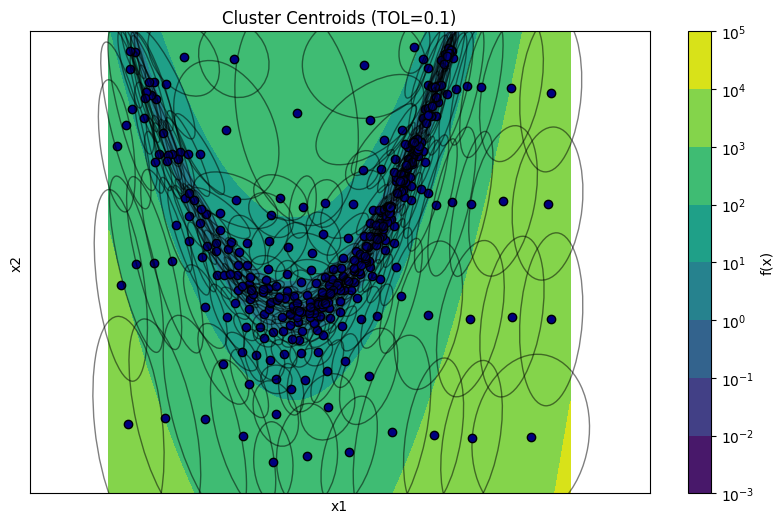

In [70]:
DOMAIN = [-2, 3]
N = 50_000
SEED = 0
TOL = 0.1

np.random.seed(SEED)
X_train = np.random.uniform(DOMAIN[0], DOMAIN[1], size=(N, 2))

result = adaptive_clustering(
    X=X_train,
    f_fn=rosenbrock,
    g_fn=rosenbrock_grad,
    TOL=TOL,
    ERROR_METRIC="Linf-local",
    NUM_INITIAL_CLUSTERS=10,
    STORE_TREE_DATA=True,
    SYNTH_BUDGET_FACTOR=100,
)
tree_data = result["tree_data"]

# Plot countrf
x = np.linspace(DOMAIN[0], DOMAIN[1], 200)
y = np.linspace(DOMAIN[0], DOMAIN[1], 200)
X, Y = np.meshgrid(x, y)
Z = rosenbrock(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)

colours = plt.cm.jet(np.linspace(0, 1, len(tree_data)))
plt.figure(figsize=(10, 6))
plt.contourf(X, Y, Z, levels=50, cmap="viridis", norm=LogNorm())
plt.colorbar(label="f(x)")

counter = 0
for level, level_data in tree_data.items():
    centroids = level_data["centroids"]
    f_values = level_data["f"]
    Qs = level_data["Q"]
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        c=colours[counter],
        label=f"Level {level} (n={len(centroids)})",
        edgecolor="k",
    )

    # Draw trust ellipse
    for i in range(centroids.shape[0]):
        mu = centroids[i]
        Q = Qs[i]
        eigvals, eigvecs = np.linalg.eigh(Q)
        order = np.argsort(eigvals)
        eigvals = eigvals[order]
        eigvecs = eigvecs[:, order]
        axes_lengths = 2 / np.sqrt(eigvals + 1e-12)
        width, height = axes_lengths
        v0 = eigvecs[:, 0]
        angle = np.degrees(np.arctan2(v0[1], v0[0]))
        ellipse = Ellipse(
            xy=mu,
            width=width,
            height=height,
            angle=angle,
            edgecolor="k",
            facecolor="none",
            linestyle="-",
            alpha=0.5,
            lw=1,
        )
        plt.gca().add_patch(ellipse)

n_clusters = len(result["centroids"])
plt.title(f"Cluster Centroids (TOL={TOL})")
plt.xlabel("x1")
plt.ylabel("x2")
plt.axis("equal")
plt.xlim(DOMAIN)
plt.ylim(DOMAIN)
plt.xticks([])
plt.yticks([])